In [1]:
import yaml
import torch
from scripts.utils import instantiate_model

from enflow.commons.sample import batched_sampling
from enflow.commons.featurization import MoleculeFeaturizer

from enflow.commons.featurization import get_mol_from_smiles
from enflow.commons.covmat import set_rdmol_positions

In [2]:
config_path = 'configs/EM2-drugs-o3.yaml' # pass config path
cfg = yaml.safe_load(open(config_path))

In [3]:
ckpt_path = 'checkpoints/EM-Phrase2/drugs-o3-harmonic/beta_0.1/epoch=419-step=493500.ckpt' # pass ckpt path
model = instantiate_model(cfg['model'], cfg['model_args'])
model.load_state_dict(torch.load(ckpt_path)['state_dict'])
model.to('cuda');

2025-12-24 13:19:17.501 | INFO     | scripts.utils:instantiate_model:139 - Loading BaseFlow with args: {'network_type': 'TorchMDDynamics', 'hidden_channels': 160, 'num_layers': 20, 'num_rbf': 64, 'rbf_type': 'expnorm', 'trainable_rbf': True, 'activation': 'silu', 'neighbor_embedding': True, 'cutoff_lower': 0.0, 'cutoff_upper': 5.0, 'max_z': 100, 'node_attr_dim': 10, 'edge_attr_dim': 1, 'attn_activation': 'silu', 'num_heads': 8, 'distance_influence': 'both', 'reduce_op': 'sum', 'qk_norm': True, 'so3_equivariant': False, 'clip_during_norm': True, 'parity_switch': 'post_hoc', 'energy_finetune': True, 'energy_finetune_weight': 0.1, 'sigma': 0.1, 'prior_type': 'harmonic', 'optimizer_type': 'AdamW', 'lr': 0.0008, 'weight_decay': 1e-08, 'lr_scheduler_type': 'CosineAnnealingWarmupRestarts', 'first_cycle_steps': 600000, 'cycle_mult': 1.0, 'max_lr': 0.0005, 'min_lr': 1e-08, 'warmup_steps': 0, 'gamma': 0.05, 'last_epoch': -1, 'lr_scheduler_monitor': 'val/loss', 'lr_scheduler_interval': 'step', 'l

#### Generate Conformation

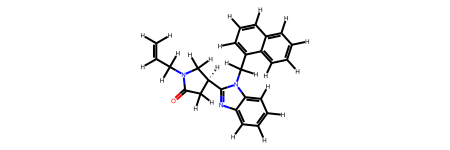

In [4]:
smiles = 'C=CCN1C[C@@H](c2nc3ccccc3n2Cc2cccc3ccccc23)CC1=O'
mol_graph = get_mol_from_smiles(smiles)
mol_graph

In [5]:
feat = MoleculeFeaturizer()
data = feat.get_data_from_smiles(smiles)
num_samples_to_generate = 8
num_sample_steps = 2
gen_position = batched_sampling(model, data, max_batch_size=8, num_samples=num_samples_to_generate, seed=42, device='cuda', energy_guided=False, return_energy=False, n_timesteps=num_sample_steps)
gen_position_guided = batched_sampling(model, data, max_batch_size=8, num_samples=num_samples_to_generate, seed=42, device='cuda', energy_guided=True, guide_scale=3, return_energy=False, n_timesteps=num_sample_steps)

Seed set to 42
Seed set to 42


#### Visualize Conformation

In [6]:
import py3Dmol # might have to pip install this for viz
from rdkit import Chem
from rdkit.Chem.Draw import IPythonConsole
IPythonConsole.molSize = (600, 600)   # Change image size
IPythonConsole.ipython_useSVG = True  # Change output to SVG
IPythonConsole.ipython_3d = True

In [7]:
mol = get_mol_from_smiles(smiles)
mol_guided = get_mol_from_smiles(smiles)
gen_idx = 0 # 0th 
mol = set_rdmol_positions(mol, gen_position[gen_idx])
mol_guided = set_rdmol_positions(mol_guided, gen_position_guided[gen_idx])

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

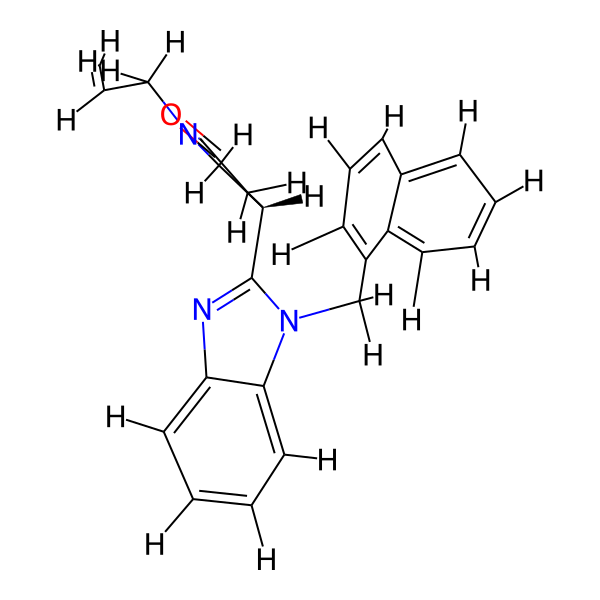

In [8]:
mol

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

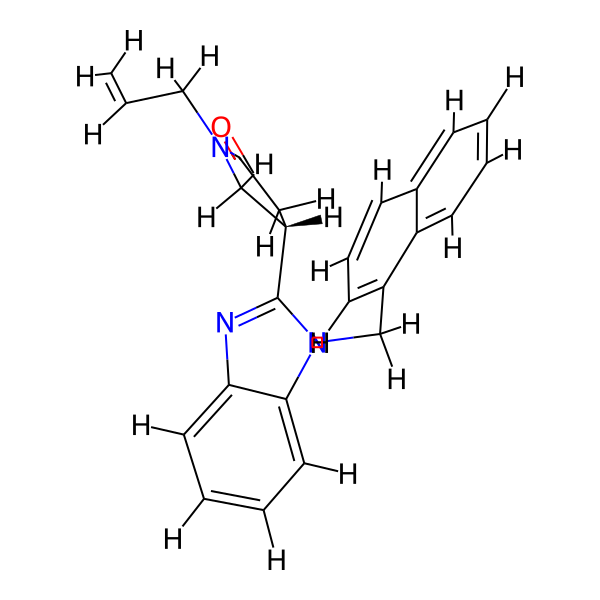

In [9]:
mol_guided